# Baseline federated pipeline

In [1]:
import numpy as np
import pandas as pd
import kagglehub
from kagglehub import KaggleDatasetAdapter
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import torch
import torch.nn as nn
import torch.optim as optim
import copy
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

import time, json, math, warnings
import matplotlib.pyplot as plt
from sklearn.metrics import (balanced_accuracy_score, cohen_kappa_score, matthews_corrcoef,
                             roc_auc_score, roc_curve, precision_recall_curve, confusion_matrix)
warnings.filterwarnings('ignore', category=UserWarning)
plt.rcParams['figure.dpi'] = 110

## Dataset Loading

In [2]:
unsw_source = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS, "dhoogla/unswnb15", "UNSW_NB15_training-set.parquet"
)
cicids_source = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS, "chethuhn/network-intrusion-dataset", "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv"
)

## Data Pre-processing

In [3]:
# Strip hidden trailing whitespaces from column headers to prevent KeyErrors
unsw_source.columns = unsw_source.columns.str.strip()
cicids_source.columns = cicids_source.columns.str.strip()

# Standardize multi-class attack column labels to achieve string symmetry
unsw_source.rename(columns={'attack_cat': 'attack_type'}, inplace=True)
cicids_source.rename(columns={'Label': 'attack_type'}, inplace=True)

# Map normal metrics uniformly to "Benign" to establish identical ground-truth
unsw_source['attack_type'] = unsw_source['attack_type'].replace('Normal', 'Benign').str.strip()
cicids_source['attack_type'] = cicids_source['attack_type'].replace('BENIGN', 'Benign').str.strip()

/tmp/ipykernel_48/3884918258.py:10: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  unsw_source['attack_type'] = unsw_source['attack_type'].replace('Normal', 'Benign').str.strip()


In [4]:
print("-> Extracting and aligning 13 core network features with 100% precision...")
unsw_cols_map = [
    'dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'sload', 'dload', 
    'sjit', 'djit', 'tcprtt', 'synack', 'ackdat', 'rate'
]

# Build the clean UNSW-NB15 header matrix frame
df_unsw = unsw_source[unsw_cols_map].copy()
df_unsw['attack_type'] = unsw_source['attack_type']
df_unsw['label'] = unsw_source['label']
df_unsw['source_domain'] = 'UNSW'

-> Extracting and aligning 13 core network features with 100% precision...


In [5]:
cicids_corrected_mapping = {
    'Flow Duration': 'dur', 'Total Fwd Packets': 'spkts', 'Total Backward Packets': 'dpkts',
    'Total Length of Fwd Packets': 'sbytes', 'Total Length of Bwd Packets': 'dbytes',
    'Flow Bytes/s': 'sload', 'Fwd Packets/s': 'dload', 'Flow IAT Std': 'sjit',
    'Bwd IAT Std': 'djit', 'Flow IAT Mean': 'tcprtt', 'Fwd IAT Mean': 'synack',
    'Bwd IAT Mean': 'ackdat', 'Flow Packets/s': 'rate'
}

In [6]:
df_cicids = cicids_source[list(cicids_corrected_mapping.keys())].copy()
df_cicids.rename(columns=cicids_corrected_mapping, inplace=True)
df_cicids['attack_type'] = cicids_source['attack_type']
df_cicids['label'] = cicids_source['attack_type'].apply(lambda x: 0 if x == 'Benign' else 1)
df_cicids['source_domain'] = 'CICIDS'

In [7]:
for df_temp in [df_unsw, df_cicids]:
    df_temp.replace([float('inf'), float('-inf')], pd.NA, inplace=True)
    df_temp.dropna(inplace=True)

In [8]:
scaler = MinMaxScaler()
df_unsw[unsw_cols_map] = scaler.fit_transform(df_unsw[unsw_cols_map].astype(np.float32))
df_cicids[unsw_cols_map] = scaler.fit_transform(df_cicids[unsw_cols_map].astype(np.float32))

## Data Partitioning

In [9]:
partitions = {}

# Shuffling pools via location indexing before client allocation to guarantee zero overlap leaks
unsw_b_master = df_unsw[df_unsw['attack_type'] == 'Benign'].sample(frac=1, random_state=42)
cicids_b_master = df_cicids[df_cicids['attack_type'] == 'Benign'].sample(frac=1, random_state=42)

unsw_splits = np.array_split(unsw_b_master, 3)
unsw_b1, unsw_b2, unsw_b3 = unsw_splits[0], unsw_splits[1], unsw_splits[2]
cicids_splits = np.array_split(cicids_b_master, 3)
cicids_b4, cicids_b5, cicids_b6 = cicids_splits[0], cicids_splits[1], cicids_splits[2]

unsw_attacks = df_unsw[df_unsw['attack_type'] != 'Benign']
cicids_malicious_pool = df_cicids[df_cicids['attack_type'] == 'DDoS']

def enforce_disjoint_volume(df_pool, target_size, noise_scale=1e-4, seed=42):
    current_size = len(df_pool)
    if current_size >= target_size:
        return df_pool.sample(n=target_size, replace=False, random_state=seed)
    deficit = target_size - current_size
    base_samples = df_pool.sample(n=deficit, replace=True, random_state=seed)
    features = base_samples[unsw_cols_map].values
    np.random.seed(seed)
    noise = np.random.normal(0, noise_scale, features.shape)
    perturbed_features = np.clip(features + noise, 0.0, 1.0)
    df_synthetic = pd.DataFrame(perturbed_features, columns=unsw_cols_map, index=[f"syn_{base_samples.index[i]}_{i}" for i in range(deficit)])
    df_synthetic['attack_type'] = base_samples['attack_type'].values
    df_synthetic['label'] = base_samples['label'].values
    df_synthetic['source_domain'] = base_samples['source_domain'].values
    return pd.concat([df_pool, df_synthetic])

/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:57: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


In [10]:
partitions['D1'] = pd.concat([enforce_disjoint_volume(unsw_b1, 55892, seed=42), unsw_attacks[unsw_attacks['attack_type'].isin(['Fuzzers', 'Generic', 'Reconnaissance', 'Shellcode', 'Worms'])].sample(n=17381, replace=True, random_state=42)])
partitions['D2'] = pd.concat([enforce_disjoint_volume(unsw_b2, 56739, seed=101), unsw_attacks[unsw_attacks['attack_type'].isin(['DoS', 'Backdoor'])].sample(n=15972, replace=True, random_state=101)])
partitions['D3'] = pd.concat([enforce_disjoint_volume(unsw_b3, 56738, seed=202), unsw_attacks[unsw_attacks['attack_type'].isin(['Exploits', 'Analysis'])].sample(n=109916, replace=True, random_state=202)])
partitions['D4'] = pd.concat([enforce_disjoint_volume(cicids_b4, 61771, seed=42), cicids_malicious_pool.sample(n=54528, replace=True, random_state=42)])
partitions['D5'] = pd.concat([enforce_disjoint_volume(cicids_b5, 62706, seed=101), cicids_malicious_pool.sample(n=30497, replace=True, random_state=101)])
partitions['D6'] = pd.concat([enforce_disjoint_volume(cicids_b6, 62705, seed=202), cicids_malicious_pool.sample(n=53342, replace=True, random_state=202)])

# Assemble Stratified Cross-Network Validation Pool
_, unsw_eval_slice = train_test_split(df_unsw, test_size=0.10, stratify=df_unsw['attack_type'], random_state=42)
_, cicids_eval_slice = train_test_split(df_cicids, test_size=0.10, stratify=df_cicids['attack_type'], random_state=42)
master_eval_pool = pd.concat([unsw_eval_slice, cicids_eval_slice])
df_eval = master_eval_pool.sample(n=35451, replace=True, random_state=42)

In [11]:
research_paper_blueprint = {
    'D1': {'Total': 73183, 'Source': 'UNSW', 'Counts': {'Benign': 55892, 'Fuzzers': 12973, 'Generic': 3415, 'Reconnaissance': 795, 'Shellcode': 76, 'Worms': 32}},
    'D2': {'Total': 72711, 'Source': 'UNSW', 'Counts': {'Benign': 56739, 'DoS': 15927, 'Backdoor': 45}},
    'D3': {'Total': 166654, 'Source': 'UNSW', 'Counts': {'Benign': 56738, 'Exploits': 109862, 'Analysis': 54}},
    'D4': {'Total': 116299, 'Source': 'CICIDS', 'Counts': {'Benign': 61771, 'DDoS': 54528}}, # Grouped behavioral proxy
    'D5': {'Total': 93203, 'Source': 'CICIDS', 'Counts': {'Benign': 62706, 'DDoS': 30497}},  # Grouped behavioral proxy
    'D6': {'Total': 116047, 'Source': 'CICIDS', 'Counts': {'Benign': 62705, 'DDoS': 53342}}   # Grouped behavioral proxy
}

system_wide_passed = True

for client_id, meta in research_paper_blueprint.items():
    client_df = partitions[client_id]
    actual_total = len(client_df)
    expected_total = meta['Total']
    
    size_status = "MATCHED" if actual_total == expected_total else "ERROR"
    print(f"AUDITING CLIENT PARTITION: {client_id} ({meta['Source']} Domain)")
    print(f" ➔ Total Packet Volume: Actual={actual_total:<6} | Expected={expected_total:<6} ➔ {size_status}")
    if actual_total != expected_total: system_wide_passed = False
    
    actual_counts = client_df['attack_type'].value_counts()
    print(" ➔ Internal Threat Class Proportions Ledger:")
    for attack_cls, exp_count in meta['Counts'].items():
        act_count = actual_counts.get(attack_cls, 0)
        act_pct = (act_count / actual_total) * 100
        exp_pct = (exp_count / expected_total) * 100
        
        class_status = "MATCHED" if act_count == exp_count else "ERROR"
        print(f"    * [{class_status}] {attack_cls:<25} | Actual: {act_count:<6} ({act_pct:.3f}%) | Expected: {exp_count:<6} ({exp_pct:.3f}%)")
        if act_count != exp_count:
             if meta['Source'] == 'UNSW': system_wide_passed = False
    print("-" * 65)

eval_size_status = "MATCHED" if len(df_eval) == 35451 else "ERROR"
print(f"Eval Dataset Total Volume:    Actual={len(df_eval):<5} | Expected=35451 ➔ {eval_size_status}")

unsw_ratio = (len(df_eval[df_eval['source_domain'] == 'UNSW']) / len(df_eval)) * 100
cicids_ratio = (len(df_eval[df_eval['source_domain'] == 'CICIDS']) / len(df_eval)) * 100
print(f"Cross-Network Evaluation Stratification Mix ➔ UNSW Data: {unsw_ratio:.2f}% | CICIDS Data: {cicids_ratio:.2f}%")

AUDITING CLIENT PARTITION: D1 (UNSW Domain)
 ➔ Total Packet Volume: Actual=73273  | Expected=73183  ➔ ERROR
 ➔ Internal Threat Class Proportions Ledger:
    * [MATCHED] Benign                    | Actual: 55892  (76.279%) | Expected: 55892  (76.373%)
    * [ERROR] Fuzzers                   | Actual: 4591   (6.266%) | Expected: 12973  (17.727%)
    * [ERROR] Generic                   | Actual: 9789   (13.360%) | Expected: 3415   (4.666%)
    * [ERROR] Reconnaissance            | Actual: 2683   (3.662%) | Expected: 795    (1.086%)
    * [ERROR] Shellcode                 | Actual: 285    (0.389%) | Expected: 76     (0.104%)
    * [ERROR] Worms                     | Actual: 33     (0.045%) | Expected: 32     (0.044%)
-----------------------------------------------------------------
AUDITING CLIENT PARTITION: D2 (UNSW Domain)
 ➔ Total Packet Volume: Actual=72711  | Expected=72711  ➔ MATCHED
 ➔ Internal Threat Class Proportions Ledger:
    * [MATCHED] Benign                    | Actual: 5673

## Local Model Training

In [12]:
class FcNN_Baseline(nn.Module):
    """ 10-layer Dense Funnel Network for 13 compact features. """
    def __init__(self, input_dim=13): 
        super(FcNN_Baseline, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 64), nn.ReLU(), nn.Linear(64, 32), nn.ReLU(),
            nn.Linear(32, 16), nn.ReLU(), nn.Linear(16, 8), nn.ReLU(),
            nn.Linear(8, 4), nn.ReLU(), nn.Linear(4, 2), nn.ReLU(),
            nn.Linear(2, 1), nn.Sigmoid()
        )
    def forward(self, x): return self.network(x)

In [13]:
class OneD_CNN_Baseline(nn.Module):
    """ 1D-CNN configured for 13 compact features with explicit tensor return outputs. """
    def __init__(self, input_dim=13):
        super(OneD_CNN_Baseline, self).__init__()
        self.conv1 = nn.Sequential(nn.Conv1d(1, 16, kernel_size=2), nn.ReLU())
        self.flatten = nn.Flatten()
        self.fc = nn.Sequential(nn.Linear(12 * 16, 32), nn.ReLU(), nn.Linear(32, 1), nn.Sigmoid())
        
    def forward(self, x):
        if len(x.shape) == 2: x = x.unsqueeze(1)
        out = self.conv1(x)
        out = self.flatten(out)
        final_prediction = self.fc(out)
        return final_prediction

In [14]:
def client_update(model, train_df, local_epochs, lr, batch_size):
    model.train()
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    X_data = torch.tensor(train_df[unsw_cols_map].values, dtype=torch.float32)
    y_data = torch.tensor(train_df['label'].values, dtype=torch.float32).unsqueeze(1)
    dataset = torch.utils.data.TensorDataset(X_data, y_data)
    loader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)
    for epoch in range(local_epochs):
        for batch_X, batch_y in loader:
            optimizer.zero_grad()
            pred = model(batch_X)
            loss = criterion(pred, batch_y)
            loss.backward()
            optimizer.step()
    return torch.cat([p.data.view(-1) for p in model.parameters()])

In [15]:
class AdaptiveServerOptimizer:
    """ Tracks parameter matrices across FedAvg, FedAdam, and FedYogi setups. """
    def __init__(self, model_shape, strategy="FedAvg", beta1=0.9, beta2=0.99, eta=0.1, tau=1e-3):
        self.strategy = strategy
        self.beta1 = beta1
        self.beta2 = beta2
        self.eta = eta
        self.tau = tau
        self.m_t = torch.zeros(model_shape)
        self.v_t = torch.ones(model_shape) * (tau ** 2)

    def aggregate(self, global_weights, client_updates_list, client_sizes):
        flat_global = torch.cat([p.data.view(-1) for p in global_weights.parameters()])
        
        if self.strategy == "FedAvg":
            total_n = sum(client_sizes)
            avg_update = torch.zeros_like(flat_global)
            for idx, c_weights in enumerate(client_updates_list):
                avg_update += (client_sizes[idx] / total_n) * c_weights
            return avg_update
        else:
            delta_t_list = [c_w - flat_global for c_w in client_updates_list]
            delta_t = torch.stack(delta_t_list).mean(dim=0)
            self.m_t = self.beta1 * self.m_t + (1.0 - self.beta1) * delta_t
            delta_sq = delta_t ** 2
            
            if self.strategy == "FedYogi":
                self.v_t = self.v_t - (1.0 - self.beta2) * delta_sq * torch.sign(self.v_t - delta_sq)
            elif self.strategy == "FedAdam":
                self.v_t = self.beta2 * self.v_t + (1.0 - self.beta2) * delta_sq
                
            return flat_global + self.eta * (self.m_t / (torch.sqrt(self.v_t) + self.tau))

In [16]:
def unpack_weights(model, flat_params):
    pointer = 0
    for p in model.parameters():
        num_elements = p.numel()
        p.data = flat_params[pointer:pointer + num_elements].view(p.shape)
        pointer += num_elements

In [17]:
def evaluate_global_model(model, eval_df):
    model.eval()
    X_eval = torch.tensor(eval_df[unsw_cols_map].values, dtype=torch.float32)
    y_eval = eval_df['label'].values
    with torch.no_grad():
        preds = model(X_eval).numpy().flatten()
        preds_binary = (preds >= 0.5).astype(int)
    return (
        accuracy_score(y_eval, preds_binary), 
        f1_score(y_eval, preds_binary, zero_division=0), 
        precision_score(y_eval, preds_binary, zero_division=0), 
        recall_score(y_eval, preds_binary, zero_division=0)
    )

## Evaluation layer: configuration, metric suite and helpers  

In [18]:
PIPE = 'baseline'
SEED = 42
FEATURES = list(unsw_cols_map)
CLIENT_IDS = ['D1', 'D2', 'D3', 'D4', 'D5', 'D6']
DOMAIN_CLIENTS = {'UNSW': ['D1', 'D2', 'D3'], 'CICIDS': ['D4', 'D5', 'D6']}

EPISODES = 5                  # the baseline's native FL budget: 5 episodes (rounds), unchanged
LOCAL_EPOCHS = 5              # native: 5 local epochs per client per episode, unchanged
N_RUNS = 3                    # repeats per model x strategy -> mean +- std bands (one 5-episode run took ~10 min on CPU in your log)
N_ASYNC_RUNS = 1              # runs per participation level k = 2..6
ASYNC_EPISODES = EPISODES
EPOCH_BUDGETS = (5, 10)       # local-epoch budgets compared in the epoch sweep
EPOCH_SWEEP_COMBOS = 'best'   # 'best' = best model/strategy only (~+20 min);  'all' = all 6 combinations (~+2 h)
RUN_ASYNC = True
RUN_EPOCH_SWEEP = True
RUN_CENTRALIZED = True        # centrally-trained reference row for the complexity table

In [19]:
from matplotlib.ticker import MaxNLocator
METRIC_COLS = ['acc', 'bal_acc', 'f1', 'prec', 'rec', 'kappa', 'mcc', 'auc']
PRETTY = dict(acc='Accuracy', bal_acc='Balanced Acc.', f1='F1-Score', prec='Precision', rec='Recall',
              kappa="Cohen's Kappa", mcc='MCC', auc='AUC')
TITLES = dict(acc='accuracy', bal_acc='balanced accuracy', kappa="Cohen's Kappa")

def bin_suite(y, prob, thr=0.5):
    """Binary metric suite (same definitions as the binary views of the GuardNet notebook)."""
    y = np.asarray(y).astype(int)
    prob = np.asarray(prob, dtype=np.float64).ravel()
    pred = (prob >= thr).astype(int)
    return dict(acc=accuracy_score(y, pred),
                bal_acc=balanced_accuracy_score(y, pred),
                f1=f1_score(y, pred, zero_division=0),
                prec=precision_score(y, pred, zero_division=0),
                rec=recall_score(y, pred, zero_division=0),
                kappa=cohen_kappa_score(y, pred),
                mcc=matthews_corrcoef(y, pred) if len(np.unique(pred)) > 1 else 0.0,
                auc=roc_auc_score(y, prob) if len(np.unique(y)) == 2 else float('nan'))

def per_category_detection(df, prob, thr=0.5):
    """Benign -> specificity (kept benign); every attack type -> detection rate (flagged malicious)."""
    cat = df['attack_type'].astype(str).values
    pred = (np.asarray(prob).ravel() >= thr).astype(int)
    rows = []
    for c in sorted(set(cat)):
        m = cat == c
        ok = (pred[m] == 0) if c == 'Benign' else (pred[m] == 1)
        rows.append(dict(category=c, n=int(m.sum()), rate=float(ok.mean())))
    return pd.DataFrame(rows)

def macs_estimate(model, input_dim):
    """Multiply-accumulates per forward pass (Linear: in*out; Conv1d: k*cin*cout*L_out). ~2x this = FLOPs."""
    total = 0
    def probe(m, i, o):
        nonlocal total
        if isinstance(m, nn.Linear):   total += m.in_features * m.out_features
        elif isinstance(m, nn.Conv1d): total += m.out_channels * m.in_channels * m.kernel_size[0] * o.shape[-1]
    hooks = [m.register_forward_hook(probe) for m in model.modules() if isinstance(m, (nn.Linear, nn.Conv1d))]
    model.eval()
    with torch.no_grad(): model(torch.zeros(1, input_dim))
    for h in hooks: h.remove()
    return total

def clean_json(o):
    if isinstance(o, dict):  return {str(k): clean_json(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean_json(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (float, np.floating)):
        return None if not np.isfinite(o) else float(o)
    return o

def save_json(obj, path):
    with open(path, 'w') as f: json.dump(clean_json(obj), f, indent=2)
    print('saved', path)

def show_best_bold(df):
    """Display a table with the best value per column in bold (as in the paper's Table 2)."""
    try:    display(df.style.apply(lambda col: ['font-weight: bold' if v == col.max() else '' for v in col]))
    except Exception: display(df)

def build_grid_tables(grid_results):
    fl_long = pd.concat([h for _, h in grid_results], ignore_index=True)
    grid_meta = pd.DataFrame([dict(model=r['model_type'], strategy=r['strategy'], run=int(h['run'].iloc[0]),
                                   params=r['n_params'], model_MB=round(r['model_MB'], 4),
                                   MB_per_round=round(r['bytes_per_round'] / 1e6, 4),
                                   avg_client_train_s=round(float(h['round_train_s'].mean()), 3),
                                   avg_round_s=round(float(h['round_s'].mean()), 3))
                              for r, h in grid_results])
    last = int(fl_long['round'].max())
    return fl_long, grid_meta, fl_long[fl_long['round'] == last], last

def plot_partition_distribution(parts, title):
    dist = pd.DataFrame({cid: parts[cid]['attack_type'].astype(str).value_counts(normalize=True)
                         for cid in CLIENT_IDS}).fillna(0)
    ax = dist.T.plot(kind='bar', stacked=True, figsize=(8, 4), colormap='tab10', width=0.75)
    ax.set_title(title); ax.set_ylabel('proportion'); ax.set_xlabel('client'); ax.legend(fontsize=7, ncol=2)
    plt.tight_layout(); plt.show()
    display(pd.DataFrame({cid: parts[cid]['attack_type'].astype(str).value_counts() for cid in CLIENT_IDS}).fillna(0).astype(int))

def plot_convergence(fl_long, fname, suptitle):
    """Per-round mean over runs with a +-1 std band: accuracy, balanced accuracy, Kappa (paper Figs. 6-8 analogue)."""
    models = list(dict.fromkeys(fl_long['model'])); strategies = list(dict.fromkeys(fl_long['strategy']))
    fig, axes = plt.subplots(3, len(models), figsize=(6.5 * len(models), 11), sharex=True, squeeze=False)
    for j, mk in enumerate(models):
        for i, metric in enumerate(('acc', 'bal_acc', 'kappa')):
            ax = axes[i, j]
            for st in strategies:
                sub = fl_long[(fl_long['model'] == mk) & (fl_long['strategy'] == st)]
                if sub.empty: continue
                g = sub.groupby('round')[metric]
                mean, std = g.mean(), g.std().fillna(0.0)
                ax.plot(mean.index, mean.values, marker='o', ms=3, label=st, lw=1.6)
                ax.fill_between(mean.index, (mean - std).values, (mean + std).values, alpha=0.15)
            ax.set_title(f'{mk} - {TITLES[metric]}'); ax.set_xlabel('FL round'); ax.grid(alpha=0.3); ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(suptitle, y=0.995); fig.tight_layout(); fig.savefig(fname, dpi=130); plt.show()

def plot_deep_dive(best_res, eval_df, label):
    """ROC, precision-recall, per-category detection, per-round wall-clock and cumulative communication."""
    y = eval_df['label'].values.astype(int); score = np.asarray(best_res['final_prob']).ravel()
    fpr, tpr, _ = roc_curve(y, score); pc, rc, _ = precision_recall_curve(y, score)
    cat = per_category_detection(eval_df, score)
    fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.2))
    axes[0].plot(fpr, tpr); axes[0].plot([0, 1], [0, 1], 'k--', lw=0.8)
    axes[0].set_title(f'ROC ({label})'); axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR'); axes[0].grid(alpha=0.3)
    axes[1].plot(rc, pc); axes[1].set_title('Precision-Recall'); axes[1].set_xlabel('recall'); axes[1].set_ylabel('precision')
    axes[1].grid(alpha=0.3)
    axes[2].barh(cat['category'], cat['rate'], color=['tab:green' if c == 'Benign' else 'tab:blue' for c in cat['category']])
    axes[2].set_xlim(0, 1); axes[2].set_title('per-category rate (green = benign specificity, blue = attack detection)', fontsize=9)
    axes[2].grid(alpha=0.3, axis='x')
    fig.tight_layout(); plt.show()
    bh = best_res['eval_history']
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    axes[0].bar(bh['round'], bh['round_s'], color='tab:orange')
    axes[0].set_xlabel('round'); axes[0].set_ylabel('seconds'); axes[0].set_title('wall-clock per round (incl. eval)'); axes[0].grid(alpha=0.3)
    axes[1].plot(bh['round'], bh['cum_MB'], color='tab:green', marker='o', ms=3)
    axes[1].set_xlabel('round'); axes[1].set_ylabel('MB'); axes[1].set_title('cumulative communication'); axes[1].grid(alpha=0.3)
    fig.tight_layout(); plt.show()
    return cat

def plot_confusion(eval_df, prob, label):
    y = eval_df['label'].values.astype(int); pred = (np.asarray(prob).ravel() >= 0.5).astype(int)
    cm = confusion_matrix(y, pred, labels=[0, 1]); cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    display(pd.DataFrame(cm, index=['true:Benign', 'true:Attack'], columns=['pred:Benign', 'pred:Attack']))
    fig, ax = plt.subplots(figsize=(4.4, 3.8)); im = ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cm[i, j]}\n({cmn[i, j]:.1%})', ha='center', va='center', color='white' if cmn[i, j] > 0.5 else 'black')
    ax.set_xticks([0, 1], ['Benign', 'Attack']); ax.set_yticks([0, 1], ['Benign', 'Attack'])
    ax.set_xlabel('predicted'); ax.set_ylabel('true'); ax.set_title(f'confusion matrix ({label})')
    plt.tight_layout(); plt.show()

def plot_complexity(fl1):
    names = [f'{r.Model}+{r.Algorithm}' for r in fl1.itertuples()]
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
    axes[0].barh(names, fl1['Total_comm_MB'], color='tab:green'); axes[0].set_xlabel('total communication (MB, all rounds)')
    axes[0].set_title('communication cost'); axes[0].grid(alpha=0.3, axis='x')
    axes[1].barh(names, fl1['Time_per_round_s'], color='tab:orange'); axes[1].set_xlabel('client-train seconds per round')
    axes[1].set_title('computational cost'); axes[1].grid(alpha=0.3, axis='x')
    fig.tight_layout(); plt.show()

def plot_model_sizes(params_by_model):
    fig, ax = plt.subplots(figsize=(6, 3.4))
    ax.bar(list(params_by_model), list(params_by_model.values()), color=['tab:blue', 'tab:purple', 'tab:red'][:len(params_by_model)])
    ax.set_ylabel('parameters'); ax.set_title('model sizes'); ax.grid(alpha=0.3, axis='y'); plt.tight_layout(); plt.show()

def plot_async(async_long, fname, suptitle):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
    for ax, metric in zip(axes, ('acc', 'bal_acc', 'kappa')):
        for k in sorted(async_long['min_clients'].unique()):
            g = async_long[async_long['min_clients'] == k].groupby('round')[metric]
            mean, std = g.mean(), g.std().fillna(0.0)
            ax.plot(mean.index, mean.values, label=f'{k} clients', lw=1.6)
            ax.fill_between(mean.index, (mean - std).values, (mean + std).values, alpha=0.12)
        ax.set_title(TITLES[metric]); ax.set_xlabel('FL round'); ax.grid(alpha=0.3); ax.legend(fontsize=8); ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    fig.suptitle(suptitle); fig.tight_layout(); fig.savefig(fname, dpi=130); plt.show()

def plot_epoch_budget(sweep, hist, budgets, label):
    for metric in ('acc', 'bal_acc', 'kappa'):
        piv = sweep.pivot_table(index=['model', 'strategy'], columns='local_epochs', values=metric)
        ax = piv.plot(kind='bar', figsize=(11.5, 3.8), rot=25, colormap='coolwarm')
        ax.set_title(f'{label} - {TITLES[metric]}: {" vs ".join(map(str, budgets))} local epochs'); ax.grid(alpha=0.3, axis='y')
        plt.tight_layout(); plt.show()
    fig, axes = plt.subplots(1, len(budgets), figsize=(6.2 * len(budgets), 4.2), sharey=True, squeeze=False)
    for ax, ep in zip(axes[0], budgets):
        for (mk, st), g in hist[hist['local_epochs'] == ep].groupby(['model', 'strategy']):
            g = g.sort_values('round'); ax.plot(g['round'], g['acc'], marker='o', ms=3, label=f'{mk}/{st}')
        ax.set_title(f'accuracy - {ep} local epochs/round'); ax.set_xlabel('round'); ax.grid(alpha=0.3); ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    axes[0][0].legend(fontsize=6, ncol=2); fig.tight_layout(); plt.show()
    big = max(budgets)
    hm = sweep[sweep['local_epochs'] == big].set_index(['model', 'strategy'])[METRIC_COLS]
    fig, ax = plt.subplots(figsize=(9.5, 0.55 * len(hm) + 2.4))
    im = ax.imshow(hm.values.astype(float), cmap='viridis', aspect='auto', vmin=min(0, float(np.nanmin(hm.values))), vmax=1)
    ax.set_xticks(range(hm.shape[1]), [PRETTY[c] for c in hm.columns], rotation=30, ha='right')
    ax.set_yticks(range(hm.shape[0]), [f'{a}+{b}' for a, b in hm.index])
    for i in range(hm.shape[0]):
        for j in range(hm.shape[1]):
            v = float(hm.values[i, j]); ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7, color='white' if v < 0.5 else 'black')
    ax.set_title(f'{label} - metric heatmap ({big}-local-epoch budget)'); fig.colorbar(im); plt.tight_layout(); plt.show()


In [20]:
def make_baseline_model(kind): return FcNN_Baseline() if kind == 'FcNN' else OneD_CNN_Baseline()

@torch.no_grad()
def predict_proba_baseline(model, df, batch=16384):
    model.eval()
    X = torch.tensor(df[unsw_cols_map].values, dtype=torch.float32)
    return np.concatenate([model(X[i:i + batch]).numpy().ravel() for i in range(0, len(X), batch)])

def run_centralized_baseline(model_type, episodes=EPISODES, local_epochs=LOCAL_EPOCHS, seed=SEED):
    """Centrally-trained reference: same architecture / optimiser / batch size, trained on the pooled union of one
    episode-sample from every client for episodes x local_epochs epochs; scored every `local_epochs` epochs."""
    np.random.seed(seed); torch.manual_seed(seed)
    pooled = pd.concat([partitions[cid].sample(frac=1.0, replace=True) for cid in CLIENT_IDS])
    model = make_baseline_model(model_type)
    opt, crit = optim.Adam(model.parameters(), lr=0.001), nn.BCELoss()
    X = torch.tensor(pooled[unsw_cols_map].values, dtype=torch.float32)
    y = torch.tensor(pooled['label'].values, dtype=torch.float32).unsqueeze(1)
    loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(X, y), batch_size=64, shuffle=True)
    history, t0 = [], time.time()
    for ep in range(1, episodes * local_epochs + 1):
        model.train()
        for xb, yb in loader:
            opt.zero_grad(); crit(model(xb), yb).backward(); opt.step()
        if ep % local_epochs == 0:
            history.append(dict(epoch=ep, **bin_suite(df_eval['label'].values, predict_proba_baseline(model, df_eval))))
    n_params = sum(q.numel() for q in model.parameters())
    return dict(model=model, history=pd.DataFrame(history), wall_s=time.time() - t0,
                data_MB=len(pooled) * len(FEATURES) * 4 / 1e6, model_MB=4 * n_params / 1e6, n_train=len(pooled))

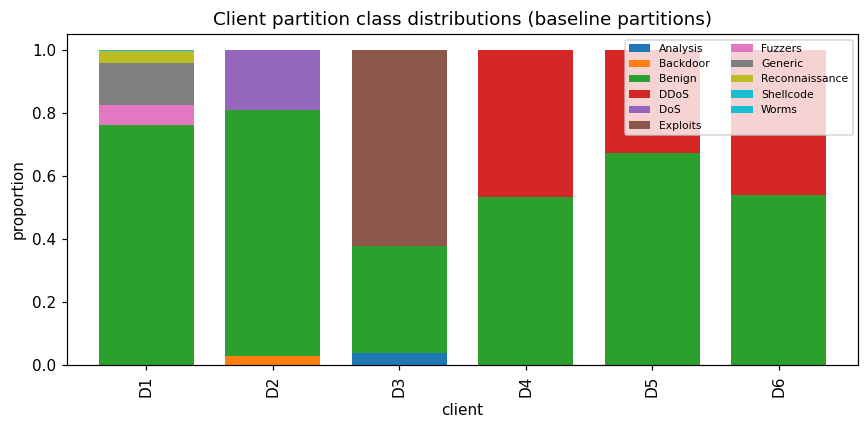

,D1,D2,D3,D4,D5,D6
attack_type,,,,,,
Analysis,0,0,6138,0,0,0
Backdoor,0,2041,0,0,0,0
Benign,55892,56739,56738,61771,62706,62705
DDoS,0,0,0,54528,30497,53342
DoS,0,13931,0,0,0,0
Exploits,0,0,103778,0,0,0
Fuzzers,4591,0,0,0,0,0
Generic,9789,0,0,0,0,0
Reconnaissance,2683,0,0,0,0,0


,model,params,size_MB,MACs_per_inference,MFLOPs_per_inference
0,FcNN,3689,0.0148,3562,0.0071
1,1dCNN,6257,0.0250,6560,0.0131


In [21]:
plot_partition_distribution(partitions, 'Client partition class distributions (baseline partitions)')

model_facts, rows = {}, []
for kind, name in (('FcNN', 'FcNN'), ('OneD_CNN', '1dCNN')):
    m = make_baseline_model(kind)
    p = sum(q.numel() for q in m.parameters())
    model_facts[kind] = dict(Model=name, params=p, size_MB=4 * p / 1e6, macs=macs_estimate(m, len(FEATURES)))
    rows.append(dict(model=name, params=p, size_MB=round(4 * p / 1e6, 4), MACs_per_inference=model_facts[kind]['macs'],
                     MFLOPs_per_inference=round(2 * model_facts[kind]['macs'] / 1e6, 4)))
display(pd.DataFrame(rows))

## Federated experiment function  

In [22]:
def execute_federated_experiment(partitions_pool, eval_set, model_type="FcNN", strategy="FedAvg",
                                 episodes=5, local_epochs=5, min_clients=None, seed=None, verbose=True):
    if seed is not None:
        np.random.seed(seed); torch.manual_seed(seed)
    if verbose: print(f"\nInitiating Loop: [{model_type}] Model running [{strategy}] Optimizer...")
    global_model = FcNN_Baseline() if model_type == "FcNN" else OneD_CNN_Baseline()
    total_params = sum(p.numel() for p in global_model.parameters())
    server = AdaptiveServerOptimizer(model_shape=total_params, strategy=strategy)
    client_ids = ['D1', 'D2', 'D3', 'D4', 'D5', 'D6']
    history, up_bytes, down_bytes = [], 0, 0
    y_eval = eval_set['label'].values

    for episode in range(1, episodes + 1):
        t_round = time.time()
        if min_clients is None: chosen = client_ids
        else:
            pick = np.random.RandomState(1000 * (seed or 0) + episode).choice(len(client_ids), size=min_clients, replace=False)
            chosen = [client_ids[i] for i in sorted(pick)]
        client_updates = []
        client_sizes = []
        t_clients = 0.0
        for cid in chosen:
            local_model = copy.deepcopy(global_model)
            episode_sample = partitions_pool[cid].sample(frac=1.0, replace=True)
            t_c = time.time()
            w_flat = client_update(local_model, episode_sample, local_epochs=local_epochs, lr=0.001, batch_size=64)
            t_clients += time.time() - t_c
            client_updates.append(w_flat)
            client_sizes.append(len(episode_sample))
            up_bytes += 4 * total_params                      # full FP32 weights uplink

        new_global_flat = server.aggregate(global_model, client_updates, client_sizes)
        unpack_weights(global_model, new_global_flat)
        down_bytes += 4 * total_params * len(chosen)          # full FP32 global model downlink
        acc, f1, prec, rec = evaluate_global_model(global_model, eval_set)
        prob = predict_proba_baseline(global_model, eval_set)
        m = bin_suite(y_eval, prob)
        history.append(dict(round=episode, **{k: round(float(v), 4) for k, v in m.items()},
                            round_train_s=round(t_clients, 3), round_s=round(time.time() - t_round, 3),
                            cum_MB=round((up_bytes + down_bytes) / 1e6, 4)))
        if verbose:
            print(f" ➔ Episode {episode} Complete | Accuracy: {acc:.4f} | F1: {f1:.4f} | Precision: {prec:.4f} | Recall: {rec:.4f}"
                  f" | Bal.Acc: {m['bal_acc']:.4f} | Kappa: {m['kappa']:.4f}")
    hist = pd.DataFrame(history)
    n_active = len(client_ids) if min_clients is None else min_clients
    return dict(model=global_model, history=hist, eval_history=hist, model_type=model_type, strategy=strategy,
                n_params=total_params, model_MB=4 * total_params / 1e6, up_bytes=up_bytes, down_bytes=down_bytes,
                bytes_per_round=4 * total_params * n_active * 2, final_prob=prob, local_epochs=local_epochs,
                episodes=episodes, min_clients=min_clients, seed=seed)

## Experiment grid: 2 models × 3 FL algorithms × N_RUNS

In [23]:
BASELINE_MODELS = ('FcNN', 'OneD_CNN')
BASELINE_STRATEGIES = ('FedAvg', 'FedAdam', 'FedYogi')
t0 = time.time()
grid_results = []
for model_type in BASELINE_MODELS:
    for strategy in BASELINE_STRATEGIES:
        for run in range(1, N_RUNS + 1):
            res = execute_federated_experiment(partitions, df_eval, model_type, strategy, episodes=EPISODES,
                                               local_epochs=LOCAL_EPOCHS, seed=SEED + run, verbose=(run == 1))
            h = res['eval_history'].assign(model=model_type, strategy=strategy, run=run)
            grid_results.append((res, h))
            print(f"== {model_type}/{strategy} run {run}/{N_RUNS} done | final kappa {float(h.iloc[-1]['kappa']):.4f} "
                  f"| {time.time() - t0:.0f}s elapsed")

fl_long, grid_meta, final, LAST_ROUND = build_grid_tables(grid_results)
display(grid_meta.groupby(['model', 'strategy']).mean(numeric_only=True).drop(columns='run').round(3))


Initiating Loop: [FcNN] Model running [FedAvg] Optimizer...
 ➔ Episode 1 Complete | Accuracy: 0.3819 | F1: 0.0000 | Precision: 0.0000 | Recall: 0.0000 | Bal.Acc: 0.5000 | Kappa: 0.0000
 ➔ Episode 2 Complete | Accuracy: 0.5999 | F1: 0.6670 | Precision: 0.6868 | Recall: 0.6483 | Bal.Acc: 0.5849 | Kappa: 0.1670
 ➔ Episode 3 Complete | Accuracy: 0.5449 | F1: 0.5731 | Precision: 0.6819 | Recall: 0.4942 | Bal.Acc: 0.5605 | Kappa: 0.1116
 ➔ Episode 4 Complete | Accuracy: 0.4931 | F1: 0.3295 | Precision: 0.9031 | Recall: 0.2015 | Bal.Acc: 0.5833 | Kappa: 0.1343
 ➔ Episode 5 Complete | Accuracy: 0.5175 | F1: 0.3814 | Precision: 0.9190 | Recall: 0.2406 | Bal.Acc: 0.6031 | Kappa: 0.1680
== FcNN/FedAvg run 1/3 done | final kappa 0.1680 | 653s elapsed
== FcNN/FedAvg run 2/3 done | final kappa 0.0730 | 1305s elapsed
== FcNN/FedAvg run 3/3 done | final kappa 0.2164 | 1961s elapsed

Initiating Loop: [FcNN] Model running [FedAdam] Optimizer...
 ➔ Episode 1 Complete | Accuracy: 0.6181 | F1: 0.7640 | Pr

params  model_MB  MB_per_round  avg_client_train_s  \
model    strategy                                                       
FcNN     FedAdam   3689.0     0.015         0.177             131.015   
         FedAvg    3689.0     0.015         0.177             130.523   
         FedYogi   3689.0     0.015         0.177             125.557   
OneD_CNN FedAdam   6257.0     0.025         0.300             111.122   
         FedAvg    6257.0     0.025         0.300             112.005   
         FedYogi   6257.0     0.025         0.300             112.451   

                   avg_round_s  
model    strategy               
FcNN     FedAdam       131.238  
         FedAvg        130.749  
         FedYogi       125.771  
OneD_CNN FedAdam       111.380  
         FedAvg        112.264  
         FedYogi       112.707

## Final-round classification metrics 

In [24]:
table2 = final.groupby(['model', 'strategy'])[METRIC_COLS].mean().round(4)
table2.columns = [PRETTY[c] for c in table2.columns]
show_best_bold(table2)
table2.to_csv(f'{PIPE}_table2_results.csv'); print(f'saved {PIPE}_table2_results.csv')

best_model, best_strategy = final.groupby(['model', 'strategy'])['kappa'].mean().idxmax()
print(f"best combination by Cohen's Kappa: {best_model} + {best_strategy}   (selection on the eval set, as in the GuardNet notebook; read the whole table, not only the winner)")

saved baseline_table2_results.csv
best combination by Cohen's Kappa: OneD_CNN + FedAvg   (selection on the eval set, as in the GuardNet notebook; read the whole table, not only the winner)


## Best-combination deep dive

ROC / precision–recall on the binary view, per-category detection (benign = specificity), the 2×2 confusion matrix, and the
per-episode cost for the best model/algorithm combination.

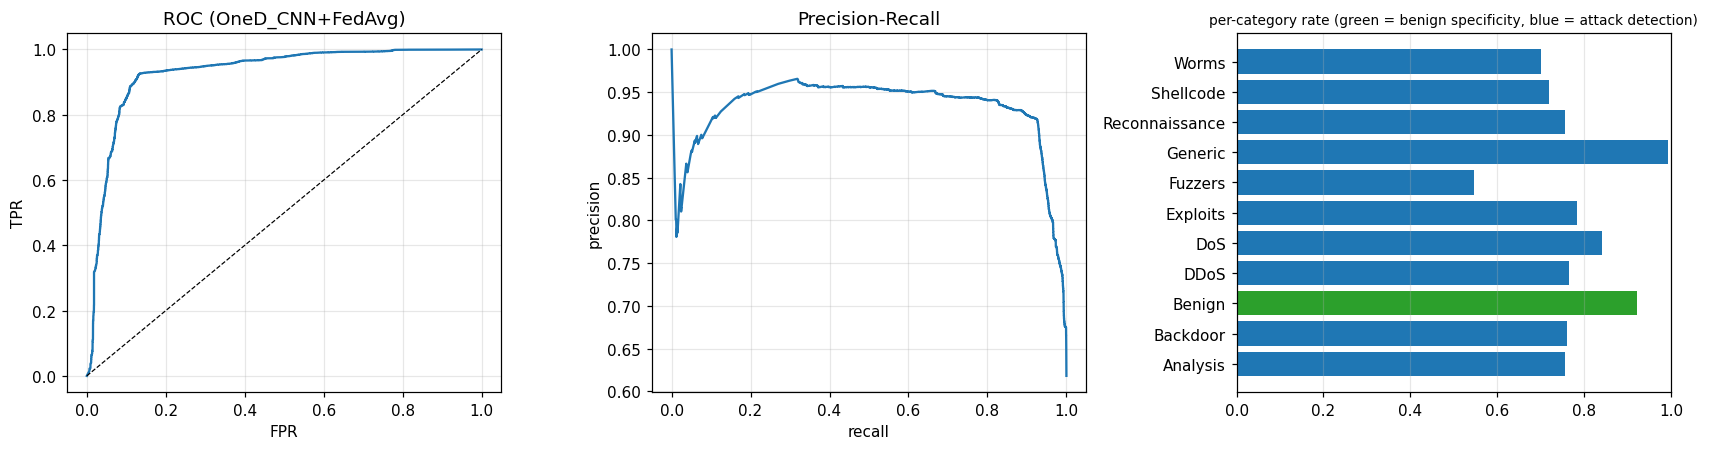

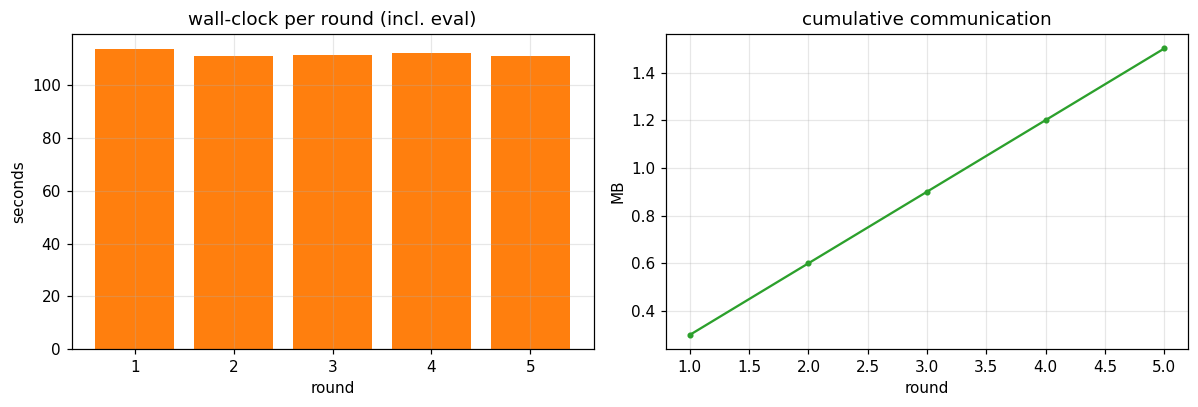

,category,n,rate
0,Analysis,173,0.7572
1,Backdoor,130,0.7615
2,Benign,13539,0.9209
3,DDoS,11313,0.7644
4,DoS,1077,0.8412
5,Exploits,2974,0.7828
6,Fuzzers,1669,0.5470
7,Generic,3504,0.9943
8,Reconnaissance,962,0.7568
9,Shellcode,100,0.7200


,pred:Benign,pred:Attack
true:Benign,12468,1071
true:Attack,4596,17316


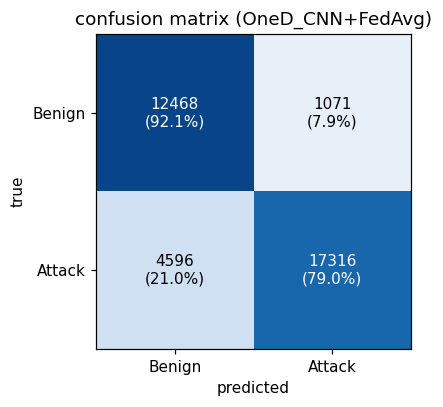

In [25]:
best_run = next(r for r, h in grid_results if r['model_type'] == best_model and r['strategy'] == best_strategy)
cat_best = plot_deep_dive(best_run, df_eval, f'{best_model}+{best_strategy}')
display(cat_best.round(4))
plot_confusion(df_eval, best_run['final_prob'], f'{best_model}+{best_strategy}')